### SETUP

In [2]:
import torch
print(f"PyTorch verzija: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only'}")

!pip install fastf1 -q

import os
import time
import pandas as pd
import numpy as np
from tqdm import tqdm
import fastf1
from google.colab import drive

drive.mount('/content/drive')
BASE_DIR = '/content/drive/MyDrive/F1_Project'
CACHE_DIR = os.path.join(BASE_DIR, 'f1_cache')
SAVE_DIR = os.path.join(BASE_DIR, 'processed_races')

os.makedirs(CACHE_DIR, exist_ok=True)
os.makedirs(SAVE_DIR, exist_ok=True)

fastf1.Cache.enable_cache(CACHE_DIR)

PyTorch verzija: 2.11.0+cu130
CUDA available: True
GPU device: Tesla T4
Mounted at /content/drive


### ISKANJE PODATKOV (NAREJENO, DRIVE)

In [ ]:

def features(laps_df):
    laps_df = laps_df.sort_values(['Driver', 'LapNumber'])

    laps_df['LapTimeSec'] = laps_df['LapTime'].dt.total_seconds()
    laps_df['StintMinLap'] = laps_df.groupby(['Driver', 'Stint'])['LapTimeSec'].transform('min')
    laps_df['Degradation'] = laps_df['LapTimeSec'] - laps_df['StintMinLap']
    laps_df['Rainfall'] = laps_df['Rainfall'].astype(int)
    laps_df['IsSafetyCar'] = laps_df['TrackStatus'].str.contains('4').astype(int)
    laps_df['IsVSC'] = laps_df['TrackStatus'].str.contains('6').astype(int)
    laps_df['PitThisLap'] = laps_df['PitInTime'].notna().astype(int)

    features_to_shift = [
        'LapTimeSec', 'Degradation', 'Position',
        'TrackStatus', 'AirTemp', 'TrackTemp', 'Rainfall'
    ]

    for feat in features_to_shift:
        laps_df[f'Prev_{feat}'] = laps_df.groupby('Driver')[feat].shift(1)

    return laps_df.dropna(subset=['Prev_LapTimeSec'])

def get_processed_schedule(start_year, end_year):
    schedule_list = []
    for year in range(start_year, end_year + 1):
        s = fastf1.get_event_schedule(year)
        # Filter for actual Grands Prix
        s = s[s['EventFormat'] != 'testing']
        for _, row in s.iterrows():
            schedule_list.append({
                'year': year,
                'round': row['RoundNumber'],
                'name': row['EventName']
            })
    return schedule_list

all_races = get_processed_schedule(2018, 2025)

for race in tqdm(all_races):
    file_path = os.path.join(SAVE_DIR, f"{race['year']}_{race['round']}.csv")

    # CHECKPOINT
    if os.path.exists(file_path):
        continue

    print(f"\nProcessing: {race['year']} {race['name']}")

    try:
        session = fastf1.get_session(race['year'], race['round'], 'R')

        session.load(laps=True, telemetry=False, weather=True, messages=False)

        laps = session.laps.copy()
        if len(laps) == 0: continue

        weather_data = session.weather_data
        laps = pd.merge_asof(laps.sort_values('Time'),
                             weather_data.sort_values('Time'),
                             on='Time',
                             direction='backward')

        df = features(laps)
        df['Year'] = race['year']
        df['Event'] = race['name']
        df.to_csv(file_path, index=False)
        time.sleep(1)

    # Limit je 500/h pozivov
    except Exception as e:
        if "RateLimitExceededError" in str(e) or "500 calls/h" in str(e):
            print(f"\n[!] STOPPING: Rate limit reached at {race['year']} {race['name']}.")
            print("Wait 1 hour")
            break
        else:
            print(f"Skipping {race['year']} {race['name']} due to other error: {e}")
            continue

100%|██████████| 173/173 [00:00<00:00, 2227.66it/s]


### OBDELAVA PODATKOV

Nalaganje 173 dirk...
Začetek učenja na 144795 vzorcih...
Epoha  10 | Loss: 3.6457 | Pit Recall: 69.28% | LR: 0.000700
Epoha  20 | Loss: 3.2691 | Pit Recall: 71.35% | LR: 0.000700
Epoha  30 | Loss: 3.1137 | Pit Recall: 71.47% | LR: 0.000700
Epoha  40 | Loss: 2.9969 | Pit Recall: 71.91% | LR: 0.000700
Epoha  50 | Loss: 2.9066 | Pit Recall: 72.47% | LR: 0.000700
Epoha  60 | Loss: 2.8550 | Pit Recall: 72.96% | LR: 0.000700
Epoha  70 | Loss: 2.7245 | Pit Recall: 73.02% | LR: 0.000700
Epoha  80 | Loss: 2.4721 | Pit Recall: 73.22% | LR: 0.000350
Epoha  90 | Loss: 2.4496 | Pit Recall: 73.91% | LR: 0.000350
Epoha 100 | Loss: 2.4062 | Pit Recall: 74.38% | LR: 0.000175
Epoha 110 | Loss: 2.2655 | Pit Recall: 75.26% | LR: 0.000175
Epoha 120 | Loss: 2.2564 | Pit Recall: 74.57% | LR: 0.000087
Epoha 130 | Loss: 2.2186 | Pit Recall: 75.29% | LR: 0.000044
Epoha 140 | Loss: 2.1339 | Pit Recall: 76.12% | LR: 0.000022
Epoha 150 | Loss: 2.1561 | Pit Recall: 75.18% | LR: 0.000011


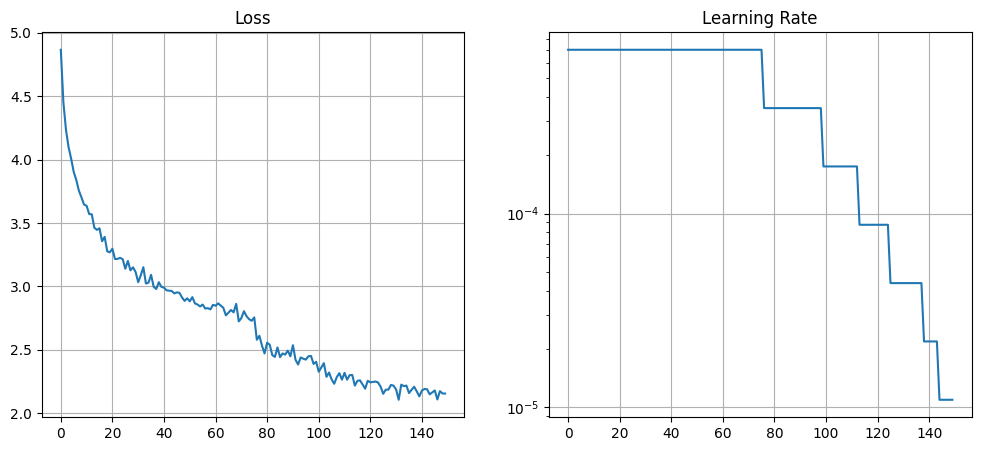

In [3]:
import os
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score
from sklearn.utils.class_weight import compute_class_weight
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
torch.manual_seed(42)
np.random.seed(42)

BASE_DIR = '/content/drive/MyDrive/F1_Project'
SAVE_DIR = os.path.join(BASE_DIR, 'processed_races')

TIRE_MAPPING = {
    'HYPERSOFT': 'SOFT', 'ULTRASOFT': 'SOFT', 'SUPERSOFT': 'SOFT',
    'SOFT': 'SOFT', 'MEDIUM': 'MEDIUM', 'HARD': 'HARD', 'SUPERHARD': 'HARD',
    'INTERMEDIATE': 'INTERMEDIATE', 'WET': 'WET', 'UNKNOWN': 'NONE', 'NONE': 'NONE'
}

def load_full_dataset(save_dir):
    all_files = [os.path.join(save_dir, f) for f in os.listdir(save_dir) if f.endswith('.csv')]
    processed_dfs = []

    print(f"Nalaganje {len(all_files)} dirk...")
    for f in all_files:
        try:
            race_df = pd.read_csv(f)
            race_df['Compound'] = race_df['Compound'].str.upper().map(TIRE_MAPPING).fillna('MEDIUM')

            total_laps = race_df['LapNumber'].max()
            for driver, data in race_df.groupby('Driver'):
                data = data.sort_values('LapNumber').copy()
                if len(data) < 5: continue

                data['StintBest'] = data.groupby('Stint')['Prev_LapTimeSec'].cummin()
                data['LapTimeDelta'] = data['Prev_LapTimeSec'] - data['StintBest']
                data['Prev_Degradation'] = data['LapTimeDelta']
                data['LapsRemaining'] = total_laps - data['LapNumber']
                data['RaceProgress'] = data['LapNumber'] / total_laps
                data['StintLength'] = data['TyreLife']

                data['TargetCompound'] = data['Compound'].shift(-1).fillna('NONE')

                processed_dfs.append(data)
        except: continue

    return pd.concat(processed_dfs, ignore_index=True)

df = load_full_dataset(SAVE_DIR)

compound_le = LabelEncoder()
all_compounds = ['SOFT', 'MEDIUM', 'HARD', 'INTERMEDIATE', 'WET', 'NONE']
compound_le.fit(all_compounds)

df['Compound_Enc'] = compound_le.transform(df['Compound'])
df['TargetCompound_Enc'] = compound_le.transform(df['TargetCompound'])

feature_cols = [
    'LapNumber',
    'TyreLife',
    'Prev_Position',
    'Prev_Degradation',
    'Prev_LapTimeSec',
    'LapTimeDelta',
    'IsSafetyCar',
    'IsVSC',
    'Compound_Enc',
    'LapsRemaining',
    'RaceProgress',
    'StintLength',
    'Prev_AirTemp',
    'Prev_TrackTemp',
    'Prev_Rainfall'
]

groups = df['Year'].astype(str) + '_' + df['Event']
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(df, groups=groups))
df_test_meta = df.loc[test_idx].copy()

scaler = StandardScaler()
X_train = scaler.fit_transform(df.loc[train_idx, feature_cols].fillna(0))
X_test = scaler.transform(df.loc[test_idx, feature_cols].fillna(0))

y_pit_train = df.loc[train_idx, 'PitThisLap'].values
y_comp_train = df.loc[train_idx, 'TargetCompound_Enc'].values

pit_only_data = df.loc[train_idx]
pit_only_data = pit_only_data[pit_only_data['PitThisLap'] == 1]
class_weights = compute_class_weight(
    'balanced',
    classes=np.arange(len(all_compounds)),
    y=pit_only_data['TargetCompound_Enc'].values
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

class StrategyModel(nn.Module):
    def __init__(self, input_dim, num_comp):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Linear(input_dim, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU()
        )
        self.pit_head = nn.Linear(64, 1)
        self.comp_head = nn.Linear(64, num_comp)

    def forward(self, x):
        feat = self.backbone(x)
        return self.pit_head(feat), self.comp_head(feat)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = StrategyModel(len(feature_cols), len(all_compounds)).to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0007)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5)

pit_weight = torch.tensor([60.0]).to(device)
criterion_pit = nn.BCEWithLogitsLoss(pos_weight=pit_weight)
criterion_comp = nn.CrossEntropyLoss(weight=class_weights_tensor.to(device))

train_loader = DataLoader(list(zip(X_train, y_pit_train, y_comp_train)), batch_size=64, shuffle=True)

print(f"Začetek učenja na {len(X_train)} vzorcih...")
history_loss = []
history_lr = []

for epoch in range(150):
    model.train()
    epoch_loss = 0
    all_p = []; all_a = []

    for b_x, b_pit, b_comp in train_loader:
        b_x, b_pit, b_comp = b_x.float().to(device), b_pit.float().to(device), b_comp.long().to(device)

        optimizer.zero_grad()
        p_pit, p_comp = model(b_x)

        loss_pit = criterion_pit(p_pit.view(-1), b_pit)

        pit_mask = (b_pit == 1)
        if pit_mask.sum() > 0:
            loss_comp = criterion_comp(p_comp[pit_mask], b_comp[pit_mask])
            loss = loss_pit + (3.0 * loss_comp)
        else:
            loss = loss_pit

        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

        all_p.extend((torch.sigmoid(p_pit).detach().cpu().numpy() > 0.75).astype(int))
        all_a.extend(b_pit.cpu().numpy())

    avg_loss = epoch_loss / len(train_loader)
    history_loss.append(avg_loss)
    current_lr = optimizer.param_groups[0]['lr']
    history_lr.append(current_lr)
    scheduler.step(avg_loss)

    if (epoch+1) % 10 == 0:
        recall = recall_score(all_a, all_p)
        print(f"Epoha {epoch+1:3d} | Loss: {avg_loss:.4f} | Pit Recall: {recall:.2%} | LR: {current_lr:.6f}")

torch.save(model.state_dict(), os.path.join(BASE_DIR, 'f1_strategy_model.pth'))
joblib.dump(scaler, os.path.join(BASE_DIR, 'scaler.pkl'))
joblib.dump(compound_le, os.path.join(BASE_DIR, 'compound_encoder.pkl'))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.plot(history_loss); plt.title('Loss'); plt.grid(True)
plt.subplot(1, 2, 2); plt.plot(history_lr); plt.title('Learning Rate'); plt.yscale('log'); plt.grid(True)
plt.show()

### CELOTNA OCENA MODELA

In [4]:
THRESHOLD = 0.75
def pit_window_evaluation(model, X_test, df_test, compound_le, threshold):
    model.eval()
    with torch.no_grad():
        inputs = torch.tensor(X_test, dtype=torch.float32).to(device)
        logits_pit, _ = model(inputs)
        probs_pit = torch.sigmoid(logits_pit).cpu().numpy().flatten()

    results = df_test.copy()
    results['Pit_Prob'] = probs_pit

    tp, fp, fn = 0, 0, 0

    for (year, event, driver), group in results.groupby(['Year', 'Event', 'Driver']):
        group = group.sort_values('LapNumber')

        actual_pit_laps = group[group['PitThisLap'] == 1]['LapNumber'].values

        pred_active = group['Pit_Prob'] >= threshold

        windows = []
        if pred_active.any():
            diff = np.diff(pred_active.astype(int), prepend=0, append=0)
            starts = np.where(diff == 1)[0]
            ends = np.where(diff == -1)[0]

            for s, e in zip(starts, ends):
                window_laps = group.iloc[s:e]['LapNumber'].values
                windows.append(set(window_laps))

        matched_actual_pits = set()
        matched_model_windows = set()

        for i, w in enumerate(windows):
            hit = False
            for pit_lap in actual_pit_laps:
                if pit_lap in w:
                    hit = True
                    matched_actual_pits.add(pit_lap)

            if hit:
                tp += 1
                matched_model_windows.add(i)
            else:
                fp += 1

        for pit_lap in actual_pit_laps:
            if pit_lap not in matched_actual_pits:
                fn += 1

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    print("-" * 50)
    print(f"STRATEŠKA EVALVACIJA NA PODLAGI OKEN (Threshold: {threshold})")
    print("-" * 50)
    print(f"Pravilno napovedana okna (TP):  {tp}")
    print(f"Napačni alarm (FP):            {fp}")
    print(f"Spregledani postanki (FN):     {fn}")
    print("-" * 50)
    print(f"Window Precision:              {precision:.2%}")
    print(f"Window Recall:                 {recall:.2%}")
    print(f"Window F1-Score:               {f1:.4f}")
    print("-" * 50)


# Zaženi to analizo
pit_window_evaluation(model, X_test, df_test_meta, compound_le, threshold=THRESHOLD)

--------------------------------------------------
STRATEŠKA EVALVACIJA NA PODLAGI OKEN (Threshold: 0.75)
--------------------------------------------------
Pravilno napovedana okna (TP):  710
Napačni alarm (FP):            946
Spregledani postanki (FN):     400
--------------------------------------------------
Window Precision:              42.87%
Window Recall:                 63.96%
Window F1-Score:               0.5134
--------------------------------------------------


--------------------------------------------------
REALNA STRATEŠKA EVALUACIJA (BREZ ŠUMA)
--------------------------------------------------
Natančnost izbire gum OB POSTANKU:    52.50%
Strateška natančnost (okno +/- 2 kroga): 29.08%
Skupno število predlaganih postankov:   4643
Število dejanskih postankov v testu:    1118
--------------------------------------------------


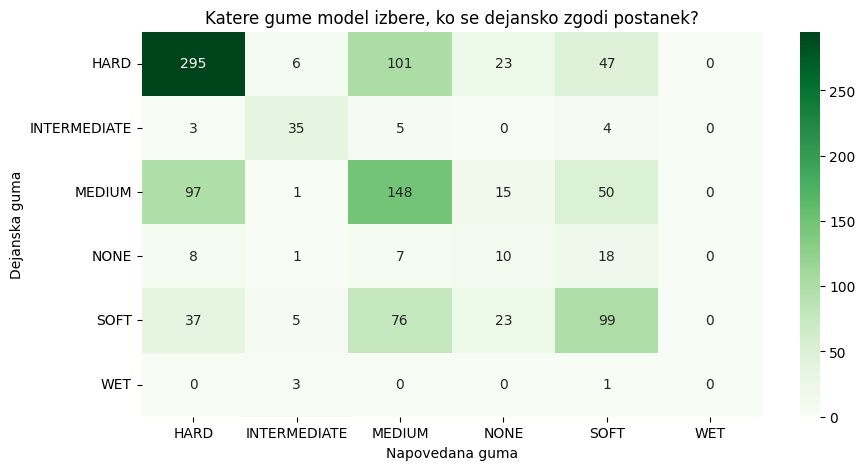

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def final_strategic_report(model, X_test, df_test, compound_le, threshold=THRESHOLD):
    model.eval()
    with torch.no_grad():
        inputs = torch.tensor(X_test, dtype=torch.float32).to(device)
        logits_pit, logits_comp = model(inputs)
        probs_pit = torch.sigmoid(logits_pit).cpu().numpy().flatten()
        preds_comp = torch.argmax(logits_comp, dim=1).cpu().numpy()

    results = df_test.copy()
    results['Pit_Prob'] = probs_pit
    results['Model_Pit'] = (probs_pit >= threshold).astype(int)
    results['Pred_Compound'] = compound_le.inverse_transform(preds_comp)

    actual_pits = results[results['PitThisLap'] == 1].copy()

    tire_accuracy = (actual_pits['Pred_Compound'] == actual_pits['TargetCompound']).mean()

    def check_window(row, all_data):
        if row['Model_Pit'] == 1:
            window = all_data[(all_data['Driver'] == row['Driver']) &
                              (all_data['Year'] == row['Year']) &
                              (all_data['Event'] == row['Event']) &
                              (all_data['LapNumber'] >= row['LapNumber'] - 2) &
                              (all_data['LapNumber'] <= row['LapNumber'] + 2)]
            return 1 if window['PitThisLap'].any() else 0
        return 0

    results['Strategic_Hit'] = results.apply(lambda r: check_window(r, results), axis=1)

    calls = results[results['Model_Pit'] == 1]
    strategic_precision = calls['Strategic_Hit'].mean() if len(calls) > 0 else 0

    print("-" * 50)
    print("REALNA STRATEŠKA EVALUACIJA (BREZ ŠUMA)")
    print("-" * 50)
    print(f"Natančnost izbire gum OB POSTANKU:    {tire_accuracy:.2%}")
    print(f"Strateška natančnost (okno +/- 2 kroga): {strategic_precision:.2%}")
    print(f"Skupno število predlaganih postankov:   {len(calls)}")
    print(f"Število dejanskih postankov v testu:    {len(actual_pits)}")
    print("-" * 50)

    if len(actual_pits) > 0:
        plt.figure(figsize=(10, 5))
        cm_tires = confusion_matrix(actual_pits['TargetCompound_Enc'],
                                   compound_le.transform(actual_pits['Pred_Compound']))
        sns.heatmap(cm_tires, annot=True, fmt='d',
                    xticklabels=compound_le.classes_, yticklabels=compound_le.classes_, cmap='Greens')
        plt.title('Katere gume model izbere, ko se dejansko zgodi postanek?')
        plt.xlabel('Napovedana guma')
        plt.ylabel('Dejanska guma')
        plt.show()

final_strategic_report(model, X_test, df_test_meta, compound_le, threshold=0.85)

### POSAMEZNA OCENA

--- Diagnostic Info for GAS in 2018 Chinese Grand Prix ---
First Lap in Data: 2.0
Last Lap in Data: 56.0
Number of actual pit stops in this data: 2
--------------------------------------------------


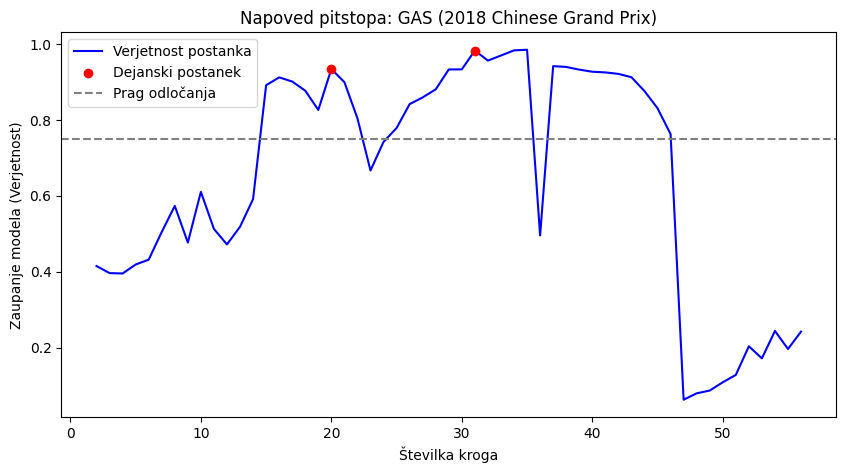

In [6]:
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    inputs = torch.tensor(X_test, dtype=torch.float32).to(device)
    logits_pit, _ = model(inputs)
    probs_pit = torch.sigmoid(logits_pit).cpu().numpy().flatten()

df_test_meta['Pit_Prob'] = probs_pit

def plot_driver_strategy(df_test, year, event, driver):
    driver_data = df_test[(df_test['Year'] == year) &
                          (df_test['Event'] == event) &
                          (df_test['Driver'] == driver)].sort_values('LapNumber')

    if driver_data.empty:
        print(f"No data found for {driver} in {year} {event}.")
        return

    print(f"--- Diagnostic Info for {driver} in {year} {event} ---")
    print(f"First Lap in Data: {driver_data['LapNumber'].min()}")
    print(f"Last Lap in Data: {driver_data['LapNumber'].max()}")
    print(f"Number of actual pit stops in this data: {driver_data['PitThisLap'].sum()}")
    print("--------------------------------------------------")

    plt.figure(figsize=(10, 5))
    plt.plot(driver_data['LapNumber'], driver_data['Pit_Prob'], label='Verjetnost postanka', color='blue')

    actual_pits = driver_data[driver_data['PitThisLap'] == 1]
    if not actual_pits.empty:
        plt.scatter(actual_pits['LapNumber'], actual_pits['Pit_Prob'], color='red', label='Dejanski postanek', zorder=5)
    plt.axhline(y=0.75, color='gray', linestyle='--', label='Prag odločanja')
    plt.title(f"Napoved pitstopa: {driver} ({year} {event})")
    plt.xlabel("Številka kroga")
    plt.ylabel("Zaupanje modela (Verjetnost)")
    plt.legend()
    plt.show()


ex = df_test_meta.groupby(['Year', 'Event', 'Driver'])['PitThisLap'].sum().reset_index()
ex = ex[ex['PitThisLap'] >= 2].iloc[0]
plot_driver_strategy(df_test_meta, ex['Year'], ex['Event'], ex['Driver'])

In [7]:
!pip list 2>/dev/null | grep -i -E "^(torch|pandas|numpy|scikit-learn|matplotlib|seaborn|fastf1|joblib|tqdm) "

fastf1                                3.8.3
joblib                                1.6.0
matplotlib                            3.10.0
numpy                                 2.1.3
pandas                                2.2.3
scikit-learn                          1.6.1
seaborn                               0.13.2
torch                                 2.11.0+cu130
tqdm                                  4.67.3
